In [1]:
def cleanup_gpu():
    import gc
    import torch

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

cleanup_gpu()

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
import os

# Xác định thư mục gốc của dự án (lùi ra 1 cấp so với thư mục notebooks)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

# Thêm thư mục gốc vào sys.path để Python có thể tìm thấy bus_benchmark
if project_root not in sys.path:
    sys.path.append(project_root)

In [4]:
import os
os.environ['ROOT_PATH'] = os.path.abspath('..')
print(os.environ["ROOT_PATH"])

/home/alexdo/Code/[Released]_Thesis_code


In [5]:
# !pip install python-dotenv

In [6]:
# !pip install wandb

## Load and sample a small dataset

In [7]:
import pandas as pd

data_set = "Rotterdam"
lau_id = "GM0599"

df_parquet = pd.read_parquet(f"../data/parquet_data/{lau_id}.parquet")
df_parquet['from_time'] = df_parquet['from_time'].dt.tz_convert('Europe/Amsterdam')
df_parquet['to_time'] = df_parquet['to_time'].dt.tz_convert('Europe/Amsterdam')
df_parquet

,lau,date,line,trip,from_stop,to_stop,from_geometry,to_geometry,from_time,to_time,travel_time,link,route
0,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480030,EBS:54480050,POINT(4.136524723663311 51.98988762419315),POINT(4.130397572689593 51.986154780523925),2022-01-01 08:35:37+01:00,2022-01-01 08:36:31+01:00,54.0,EBS:54480030>EBS:54480050,3976
1,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480050,EBS:54480330,POINT(4.130397572689593 51.986154780523925),POINT(4.131337732880599 51.98117586736649),2022-01-01 08:36:31+01:00,2022-01-01 08:37:34+01:00,63.0,EBS:54480050>EBS:54480330,3976
2,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480330,EBS:54480240,POINT(4.131337732880599 51.98117586736649),POINT(4.128562428750497 51.978916906872264),2022-01-01 08:37:34+01:00,2022-01-01 08:38:14+01:00,40.0,EBS:54480330>EBS:54480240,3976
3,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480240,EBS:54480151,POINT(4.128562428750497 51.978916906872264),POINT(4.127670942042243 51.975931967151375),2022-01-01 08:38:14+01:00,2022-01-01 08:39:20+01:00,66.0,EBS:54480240>EBS:54480151,3976
4,GM0599,2022-01-01,EBS:3031,EBS:7003:0,EBS:54480030,EBS:54480050,POINT(4.136524723663311 51.98988762419315),POINT(4.13038326987833 51.98614563862863),2022-01-01 09:07:00+01:00,2022-01-01 09:07:54+01:00,54.0,EBS:54480030>EBS:54480050,3976
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7375242,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA0901,RET:HA6638,POINT(4.529004551279279 51.8791678089587),POINT(4.534286043827047 51.88096806642176),2024-12-23 00:00:21+01:00,2024-12-23 00:01:04+01:00,43.0,RET:HA0901>RET:HA6638,214955
7375243,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA6638,RET:HA0557,POINT(4.534546249827456 51.88103287648235),POINT(4.535019668592061 51.88594415405373),2024-12-23 00:01:23+01:00,2024-12-23 00:02:46+01:00,83.0,RET:HA6638>RET:HA0557,214955
7375244,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA0557,RET:HA0372,POINT(4.535019668592061 51.88594415405373),POINT(4.535262203322954 51.88694366086019),2024-12-23 00:02:46+01:00,2024-12-23 00:03:59+01:00,73.0,RET:HA0557>RET:HA0372,214955
7375245,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA0372,RET:HA0298,POINT(4.535262203322954 51.88694366086019),POINT(4.540399663754044 51.88719653284673),2024-12-23 00:03:59+01:00,2024-12-23 00:04:02+01:00,3.0,RET:HA0372>RET:HA0298,214955


In [8]:
# Đếm tổng số lượng route khác nhau trong bộ dữ liệu gốc
total_unique_routes = df_parquet['route'].nunique()

print(f"Tổng số route có trong dữ liệu gốc: {total_unique_routes}")

Tổng số route có trong dữ liệu gốc: 589


In [9]:
route = df_parquet['route'].mode()[0]
df = df_parquet[df_parquet["route"] == route]
data_set_name = f"{data_set}_{route}"
data_set_name

'Rotterdam_148457'

In [10]:
# 1. Xem số lượng record
num_records = len(df)
print(f"Số lượng record của route '{route}': {num_records:,}")

# 2. Xem số lượng stop points (trạm dừng)
# Gộp tất cả các trạm dừng từ cột 'from_stop' và 'to_stop' lại và đếm số lượng các trạm duy nhất
unique_stops = set(df['from_stop']).union(set(df['to_stop']))
print(f"Số lượng stop points (trạm dừng) duy nhất trong tuyến: {len(unique_stops)}")

Số lượng record của route '148457': 196,400
Số lượng stop points (trạm dừng) duy nhất trong tuyến: 9


# Cấu hình tham số

In [11]:
checkpoints_dir = "./checkpoints"

# Tham số dataset
FFILL_LIMIT=8
IS_CALCULATE_RESIDUALS=True
IS_NORMALIZE=True

# Tham số Training cơ bản 
SEQ_LEN=32                          # Input sequence length (encoder length)
PRINT_METRICS="per_horizon"         # Set per_horizon hoặc overall
N_EPOCHS=50                         # Số epoch tối đa
BATCH_SIZE=512
LR=1e-3                             # Learning rate
PATIENCE=10                         # Early stopping patience
MAX_GRAD_NORM=5.0

# Siêu tham số đặc thù của TFT 
HIDDEN_SIZE=64                      # Kích thước embedding và LSTM (d_model)
NUM_HEADS=4                         # Số lượng head trong cơ chế Attention
DROPOUT_RATE=0.1                    # Tỷ lệ Dropout
NUM_QUANTILES=3                     # Số lượng phân vị cho Quantile Loss (mặc định: p10, p50, p90)
NUM_STACKS=1                        # Số lớp Attention

# Overview of dataset for training and eval

In [12]:
from bus_benchmark.experiments.fixed_interval_dataset import FixedIntervalDataset

fixed_interval_dataset = FixedIntervalDataset(
    df,
    n_splits=5,
    freq="15min",
    ha_agg_func="median",
    ffill_limit=FFILL_LIMIT,
    mad_thresh=3*1.4826,
    interpolate_ha=True,
    add_time_feat=False,
    calculate_residuals=IS_CALCULATE_RESIDUALS,
    normalize=IS_NORMALIZE
)

INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 1: train=29840 (from 2022-04-04 05:52:50+02:00 to 2022-08-21 11:56:27.638888888+02:00), val=6064 (from 2022-08-21 11:56:27.638888888+02:00 to 2022-09-18 08:21:11.166666666+02:00), test=38696 (from 2022-09-18 08:21:11.166666666+02:00 to 2023-03-04 09:49:32.333333332+01:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 2: train=61586 (from 2022-04-04 05:52:50+02:00 to 2023-01-07 17:00:05.277777776+01:00), val=13014 (from 2023-01-07 17:00:05.277777776+01:00 to 2023-03-04 09:49:32.333333332+01:00), test=35546 (from 2023-03-04 09:49:32.333333332+01:00 to 2023-08-18 13:17:53.499999998+02:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 3: train=93480 (from 2022-04-04 05:52:50+02:00 to 2023-05-27 00:03:42.916666672+02:00), val=16666 (from 2023-05-27 00:03:42.916666672+02:00 to 2023-08-18 13:17:53.499999998+02:00), test=29486 (from 2023-08-18 13:17:53.499999998+02:00 to 2024-02-01 14:46:14.666666664+01:00)

In [13]:
# Hiển thị mẫu sample từ dataset
df_train, df_val, df_test, df_ha, scaler, absolut_matrix_train = fixed_interval_dataset.data_set[4]

display(df_train)

link,RET:HA6191>RET:HA6484,RET:HA6484>RET:HA0895,RET:HA0895>RET:HA0524,RET:HA0524>RET:HA0896,RET:HA0896>RET:HA6637,RET:HA6637>RET:HA0839,RET:HA0839>RET:HA6118,RET:HA6118>RET:HA7101
2022-04-04 05:45:00+02:00,-0.624745,0.994897,0.909975,0.189591,0.492749,NaN,NaN,NaN
2022-04-04 06:00:00+02:00,1.405677,0.000000,0.909975,0.189591,0.492749,0.627535,1.239220,0.711691
2022-04-04 06:15:00+02:00,1.405677,0.000000,0.909975,1.169146,-0.341134,0.336726,1.376911,1.156498
2022-04-04 06:30:00+02:00,-0.156186,0.000000,0.909975,1.169146,-0.341134,0.336726,1.376911,1.156498
2022-04-04 06:45:00+02:00,-0.156186,0.000000,0.341241,1.074350,-0.644364,-0.244892,-0.757301,1.134258
...,...,...,...,...,...,...,...,...
2024-02-29 10:00:00+01:00,-0.624745,-1.537568,-0.454987,-0.600372,1.288727,-0.811204,-0.240959,2.268515
2024-02-29 10:15:00+01:00,-0.624745,-1.537568,-0.454987,-0.600372,1.288727,-0.811204,-0.240959,-0.778412
2024-02-29 10:30:00+01:00,-0.624745,-1.537568,-0.454987,-0.600372,1.288727,-0.811204,-0.240959,-0.778412
2024-02-29 10:45:00+01:00,-0.624745,-1.537568,-0.568734,1.011153,2.274224,1.454044,1.101528,-0.778412


In [14]:
for train, val, test in fixed_interval_dataset.splits:
    print(f'Train: {len(train)}, Val: {len(val)}, Test: {len(test)}')

Train: 29840, Val: 6064, Test: 38696
Train: 61586, Val: 13014, Test: 35546
Train: 93480, Val: 16666, Test: 29486
Train: 119472, Val: 20160, Test: 27424
Train: 144782, Val: 22274, Test: 29343


# Sliding window

In [15]:
# Import TFTLongDataset dành cho kiến trúc Temporal Fusion Transformer (Entity-based Long Format)
from bus_benchmark.experiments.tft_long_dataset import TFTLongDataset

horizons = (1, 2, 4, 8)
seq_len = 32
decoder_len = max(horizons)  # TFT dự báo chuỗi liên tục độ dài decoder_len (= 8)

for df_train, df_val, df_test, df_ha, scaler, absolut_matrix_train in fixed_interval_dataset.data_set:
    print(f'Train: {df_train.shape}, Val: {df_val.shape}, Test: {df_test.shape}')
    print(f'Train timestamps: {df_train.index[0]} to {df_train.index[-1]}')
    print(f'Val timestamps: {df_val.index[0]} to {df_val.index[-1]}')
    print(f'Test timestamps: {df_test.index[0]} to {df_test.index[-1]}')
    
    # Khởi tạo TFTLongDataset với encoder_len, decoder_len và các temporal / entity features
    ds_train = TFTLongDataset(
        df=df_train,
        encoder_len=seq_len,
        decoder_len=decoder_len,
        df_ha=df_ha,
        align_windows=True,        # Căn chỉnh cửa sổ thời gian đồng bộ trên toàn bộ links
        use_is_imputed=True,       # Mask đánh dấu điểm dữ liệu forward-fill / nội suy
        use_tod=True,              # Feature thời gian trong ngày (sin_tod, cos_tod)
        use_dow=True,              # Feature ngày trong tuần (sin_dow, cos_dow)
        use_pattern_profile=False  # Đặt True nếu muốn nạp thêm median pattern profile từ df_ha
    )
    ds_val = TFTLongDataset(
        df=df_val,
        encoder_len=seq_len,
        decoder_len=decoder_len,
        df_ha=df_ha,
        align_windows=True,
        use_is_imputed=True,
        use_tod=True,
        use_dow=True,
        use_pattern_profile=False
    )
    ds_test = TFTLongDataset(
        df=df_test,
        encoder_len=seq_len,
        decoder_len=decoder_len,
        df_ha=df_ha,
        align_windows=True,
        use_is_imputed=True,
        use_tod=True,
        use_dow=True,
        use_pattern_profile=False
    )

    for name, ds in [('Train', ds_train), ('Val', ds_val), ('Test', ds_test)]:
        n_valid_windows = len(set(ds.valid_pairs[:, 0])) if len(ds) > 0 else 0
        print(f'{name} TFT: {len(ds)} samples ({n_valid_windows} valid windows x {ds.n_links} links | lý thuyết {ds.n_windows} windows)')
    print("-" * 50)

INFO:bus_benchmark.experiments.tft_long_dataset:Created 20664 entity-based samples from 13321 time windows across 8 links
INFO:bus_benchmark.experiments.tft_long_dataset:Created 4280 entity-based samples from 2587 time windows across 8 links
INFO:bus_benchmark.experiments.tft_long_dataset:Created 25768 entity-based samples from 15998 time windows across 8 links
INFO:bus_benchmark.experiments.tft_long_dataset:Created 43408 entity-based samples from 26698 time windows across 8 links
INFO:bus_benchmark.experiments.tft_long_dataset:Created 8368 entity-based samples from 5305 time windows across 8 links
INFO:bus_benchmark.experiments.tft_long_dataset:Created 22584 entity-based samples from 16003 time windows across 8 links
INFO:bus_benchmark.experiments.tft_long_dataset:Created 64928 entity-based samples from 40061 time windows across 8 links
INFO:bus_benchmark.experiments.tft_long_dataset:Created 11048 entity-based samples from 7982 time windows across 8 links
INFO:bus_benchmark.experiment

Train: (13360, 8), Val: (2626, 8), Test: (16037, 8)
Train timestamps: 2022-04-04 05:45:00+02:00 to 2022-08-21 09:30:00+02:00
Val timestamps: 2022-08-21 15:45:00+02:00 to 2022-09-18 00:00:00+02:00
Test timestamps: 2022-09-18 08:45:00+02:00 to 2023-03-04 08:45:00+01:00
Train TFT: 20664 samples (2583 valid windows x 8 links | lý thuyết 13321 windows)
Val TFT: 4280 samples (535 valid windows x 8 links | lý thuyết 2587 windows)
Test TFT: 25768 samples (3221 valid windows x 8 links | lý thuyết 15998 windows)
--------------------------------------------------
Train: (26737, 8), Val: (5344, 8), Test: (16042, 8)
Train timestamps: 2022-04-04 05:45:00+02:00 to 2023-01-07 16:45:00+01:00
Val timestamps: 2023-01-07 17:00:00+01:00 to 2023-03-04 08:45:00+01:00
Test timestamps: 2023-03-04 10:00:00+01:00 to 2023-08-18 13:15:00+02:00
Train TFT: 43408 samples (5426 valid windows x 8 links | lý thuyết 26698 windows)
Val TFT: 8368 samples (1046 valid windows x 8 links | lý thuyết 5305 windows)
Test TFT: 225

# Training mô hình TFT

In [16]:
# 1. Khởi tạo Dataset
# Sử dụng FixedIntervalDataset để đọc dữ liệu gốc và 
# tự động tính toán metadata (dành cho static covariates).
import time
from bus_benchmark.experiments.fixed_interval_dataset import FixedIntervalDataset

fixed_interval_dataset = FixedIntervalDataset(
    df,
    n_splits=5,
    freq="15min",
    ha_agg_func="median",
    ffill_limit=FFILL_LIMIT,
    mad_thresh=3*1.4826,
    interpolate_ha=True,
    add_time_feat=False,
    calculate_residuals=IS_CALCULATE_RESIDUALS,
    normalize=IS_NORMALIZE
)


# 2. Khởi tạo TFT Model Trainer
from bus_benchmark.experiments.model.tft_long_model_trainer import TFTLongModelTrainer

fixed_interval_model_trainer = TFTLongModelTrainer(
    base_dataset=fixed_interval_dataset,
    data_set_name=data_set_name,

    # ── Tham số lựa chọn Features ──
    use_link_id=True,                     
    use_link_length=True,                          
    use_tod=True,                             
    use_dow=True,                             
    use_is_imputed=True,      
    use_stop_sequence=True,
    use_pattern_profile=True,

    # ── Các cấu hình training ──
    seq_len=SEQ_LEN,
    horizons=(1, 2, 4, 8),
    print_metrics=PRINT_METRICS,
    n_epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LR,
    patience=PATIENCE,
    max_grad_norm=MAX_GRAD_NORM,
    hidden_size=HIDDEN_SIZE,
    num_heads=NUM_HEADS,
    dropout_rate=DROPOUT_RATE,
    num_quantiles=NUM_QUANTILES,
    num_stacks=NUM_STACKS,
    verbose=True
)

# 3. Cố định random seed để kết quả ổn định và lặp lại được
fixed_interval_model_trainer._setup_seed(42)

# 4.   Kích hoạt toàn bộ quy trình: Train -> Eval -> Test 
#      Mô hình sẽ tự động trích xuất median (p50) cho bước Test 
#      để đồng nhất dạng output (B, S, H) với pipeline metrics của project.
# 4.1. Ghi nhận thời gian bắt đầu
start_time = time.time()

fixed_interval_model_trainer.run_experiment()

# 4.2. Ghi nhận thời gian kết thúc
end_time = time.time()

# Lưu checkpoint
fixed_interval_model_trainer.save_checkpoints(checkpoints_dir)

INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 1: train=29840 (from 2022-04-04 05:52:50+02:00 to 2022-08-21 11:56:27.638888888+02:00), val=6064 (from 2022-08-21 11:56:27.638888888+02:00 to 2022-09-18 08:21:11.166666666+02:00), test=38696 (from 2022-09-18 08:21:11.166666666+02:00 to 2023-03-04 09:49:32.333333332+01:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 2: train=61586 (from 2022-04-04 05:52:50+02:00 to 2023-01-07 17:00:05.277777776+01:00), val=13014 (from 2023-01-07 17:00:05.277777776+01:00 to 2023-03-04 09:49:32.333333332+01:00), test=35546 (from 2023-03-04 09:49:32.333333332+01:00 to 2023-08-18 13:17:53.499999998+02:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 3: train=93480 (from 2022-04-04 05:52:50+02:00 to 2023-05-27 00:03:42.916666672+02:00), val=16666 (from 2023-05-27 00:03:42.916666672+02:00 to 2023-08-18 13:17:53.499999998+02:00), test=29486 (from 2023-08-18 13:17:53.499999998+02:00 to 2024-02-01 14:46:14.666666664+01:00)

In [17]:
# 5. Tính toán và in ra (tính bằng giây)
training_time_seconds = end_time - start_time
training_time_minutes = training_time_seconds / 60
training_time_hours = training_time_minutes / 60

print(f"\n=========================================")
print(f"Hoàn thành đào tạo mô hình!")
print(f"Tổng thời gian: {training_time_seconds:.2f} giây")
print(f"Tương đương : {training_time_minutes:.2f} phút")
if training_time_hours > 1:
    print(f"Tương đương : {training_time_hours:.2f} giờ")
print(f"=========================================")


Hoàn thành đào tạo mô hình!
Tổng thời gian: 715.30 giây
Tương đương : 11.92 phút


In [19]:
import time

start_test_time = time.time()
fixed_interval_model_trainer.evaluate_only()
end_test_time = time.time()

INFO:bus_benchmark.experiments.model.tft_long_model_trainer:Evaluating split 0/5 from checkpoint
INFO:bus_benchmark.experiments.tft_long_dataset:Created 25768 entity-based samples from 15998 time windows across 8 links
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 1 | MAE 9.8537 | RMSE 19.4854 | ICP 0.7857 | MIL 30.8714
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 2 | MAE 13.6864 | RMSE 21.8258 | ICP 0.7631 | MIL 39.1964
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 4 | MAE 14.8580 | RMSE 22.3236 | ICP 0.7525 | MIL 42.9432
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 8 | MAE 14.6228 | RMSE 21.8949 | ICP 0.7528 | MIL 41.9922
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:Evaluating split 1/5 from checkpoint
INFO:bus_benchmark.experiments.tft_long_dataset:Created 22584 entity-based samples from 16003 time windows across 8 links
INFO:bus_benchmark.experiments.model.tft_long_model

In [20]:
test_time_seconds = end_test_time - start_test_time
test_time_minutes = test_time_seconds / 60
test_time_hours = test_time_minutes / 60

print(f"\n=========================================")
print(f"Hoàn thành test!")
print(f"Tổng thời gian: {test_time_seconds:.2f} giây")
print(f"Tương đương : {test_time_minutes:.2f} phút")
if test_time_hours > 1:
    print(f"Tương đương : {test_time_hours:.2f} giờ")
print(f"=========================================")


Hoàn thành test!
Tổng thời gian: 6.09 giây
Tương đương : 0.10 phút


# Load checkpoint và chạy đánh giá

## Load checkpoint

In [21]:
# 1. Khởi tạo Dataset
# Lưu ý: TFT sử dụng FixedIntervalDataset để đọc dữ liệu gốc và 
# tự động tính toán metadata (dành cho static covariates).
from bus_benchmark.experiments.fixed_interval_dataset import FixedIntervalDataset

fixed_interval_dataset = FixedIntervalDataset(
    df,
    n_splits=5,
    freq="15min",
    ha_agg_func="median",
    ffill_limit=FFILL_LIMIT,
    mad_thresh=3*1.4826,
    interpolate_ha=True,
    add_time_feat=False,
    calculate_residuals=IS_CALCULATE_RESIDUALS,
    normalize=IS_NORMALIZE
)

INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 1: train=29840 (from 2022-04-04 05:52:50+02:00 to 2022-08-21 11:56:27.638888888+02:00), val=6064 (from 2022-08-21 11:56:27.638888888+02:00 to 2022-09-18 08:21:11.166666666+02:00), test=38696 (from 2022-09-18 08:21:11.166666666+02:00 to 2023-03-04 09:49:32.333333332+01:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 2: train=61586 (from 2022-04-04 05:52:50+02:00 to 2023-01-07 17:00:05.277777776+01:00), val=13014 (from 2023-01-07 17:00:05.277777776+01:00 to 2023-03-04 09:49:32.333333332+01:00), test=35546 (from 2023-03-04 09:49:32.333333332+01:00 to 2023-08-18 13:17:53.499999998+02:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 3: train=93480 (from 2022-04-04 05:52:50+02:00 to 2023-05-27 00:03:42.916666672+02:00), val=16666 (from 2023-05-27 00:03:42.916666672+02:00 to 2023-08-18 13:17:53.499999998+02:00), test=29486 (from 2023-08-18 13:17:53.499999998+02:00 to 2024-02-01 14:46:14.666666664+01:00)

In [22]:
# 2. Khởi tạo TFT Model Trainer
from bus_benchmark.experiments.model.tft_long_model_trainer import TFTLongModelTrainer

fixed_interval_model_trainer = TFTLongModelTrainer(
    base_dataset=fixed_interval_dataset,
    data_set_name=data_set_name,

    # ── Tham số lựa chọn Features ──
    use_link_id=True,                     
    use_link_length=True,                          
    use_tod=True,                             
    use_dow=True,                                
    use_is_imputed=True,       
    use_stop_sequence=True,  
    use_pattern_profile=True,
    
    # ── Các cấu hình training ──
    seq_len=SEQ_LEN,
    horizons=(1, 2, 4, 8),
    print_metrics=PRINT_METRICS,
    n_epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LR,
    patience=PATIENCE,
    max_grad_norm=MAX_GRAD_NORM,
    hidden_size=HIDDEN_SIZE,
    num_heads=NUM_HEADS,
    dropout_rate=DROPOUT_RATE,
    num_quantiles=NUM_QUANTILES,
    num_stacks=NUM_STACKS,
    verbose=True
)

# 3. Cố định random seed để kết quả ổn định và lặp lại được
fixed_interval_model_trainer._setup_seed(42)

INFO:bus_benchmark.experiments.model.model_trainer_base:Initialized trainer on device: cuda


In [23]:
fixed_interval_model_trainer.load_checkpoints(checkpoints_dir)

INFO:bus_benchmark.experiments.model.tft_long_model_trainer:Loaded 5 checkpoints from ./checkpoints


## Evaluation

In [24]:
import time

start_test_time = time.time()
fixed_interval_model_trainer.evaluate_only()
end_test_time = time.time()

INFO:bus_benchmark.experiments.model.tft_long_model_trainer:Evaluating split 0/5 from checkpoint
INFO:bus_benchmark.experiments.tft_long_dataset:Created 25768 entity-based samples from 15998 time windows across 8 links
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 1 | MAE 9.8537 | RMSE 19.4854 | ICP 0.7857 | MIL 30.8714
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 2 | MAE 13.6864 | RMSE 21.8258 | ICP 0.7631 | MIL 39.1964
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 4 | MAE 14.8580 | RMSE 22.3236 | ICP 0.7525 | MIL 42.9432
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 8 | MAE 14.6228 | RMSE 21.8949 | ICP 0.7528 | MIL 41.9922
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:Evaluating split 1/5 from checkpoint
INFO:bus_benchmark.experiments.tft_long_dataset:Created 22584 entity-based samples from 16003 time windows across 8 links
INFO:bus_benchmark.experiments.model.tft_long_model

In [25]:
test_time_seconds = end_test_time - start_test_time
test_time_minutes = test_time_seconds / 60
test_time_hours = test_time_minutes / 60

print(f"\n=========================================")
print(f"Hoàn thành test!")
print(f"Tổng thời gian: {test_time_seconds:.2f} giây")
print(f"Tương đương : {test_time_minutes:.2f} phút")
if test_time_hours > 1:
    print(f"Tương đương : {test_time_hours:.2f} giờ")
print(f"=========================================")


Hoàn thành test!
Tổng thời gian: 6.50 giây
Tương đương : 0.11 phút


In [26]:
# Lấy dict interpretation (cho model / split cuối cùng)
interpretation = fixed_interval_model_trainer.get_interpretation(split_idx=-1)

# In giá trị attention
attention_values = interpretation["attention"].numpy()
attention_values = attention_values / attention_values.sum()

print("=== TRỌNG SỐ THỜI GIAN (ATTENTION WEIGHT) ===")
for i, val in enumerate(attention_values):
    time_step = i - fixed_interval_model_trainer.seq_len
    print(f"Time index {time_step:>3}: {val * 100:>6.2f} %")

INFO:bus_benchmark.experiments.tft_long_dataset:Created 13824 entity-based samples from 16002 time windows across 8 links


=== TRỌNG SỐ THỜI GIAN (ATTENTION WEIGHT) ===
Time index -32:   3.27 %
Time index -31:   3.25 %
Time index -30:   3.23 %
Time index -29:   3.22 %
Time index -28:   3.21 %
Time index -27:   3.19 %
Time index -26:   3.17 %
Time index -25:   3.15 %
Time index -24:   3.14 %
Time index -23:   3.12 %
Time index -22:   3.10 %
Time index -21:   3.08 %
Time index -20:   3.07 %
Time index -19:   3.05 %
Time index -18:   3.04 %
Time index -17:   3.03 %
Time index -16:   3.02 %
Time index -15:   3.00 %
Time index -14:   2.99 %
Time index -13:   2.98 %
Time index -12:   2.97 %
Time index -11:   2.96 %
Time index -10:   2.95 %
Time index  -9:   2.95 %
Time index  -8:   2.94 %
Time index  -7:   2.94 %
Time index  -6:   2.94 %
Time index  -5:   2.96 %
Time index  -4:   2.98 %
Time index  -3:   3.03 %
Time index  -2:   3.12 %
Time index  -1:   3.26 %
Time index   0:   1.68 %


## Interpretability

INFO:bus_benchmark.experiments.tft_long_dataset:Created 13824 entity-based samples from 16002 time windows across 8 links


{'attention': <Figure size 800x400 with 1 Axes>,
 'static_variables': <Figure size 800x400 with 1 Axes>,
 'historical_variables': <Figure size 800x400 with 1 Axes>,
 'future_variables': <Figure size 800x400 with 1 Axes>}

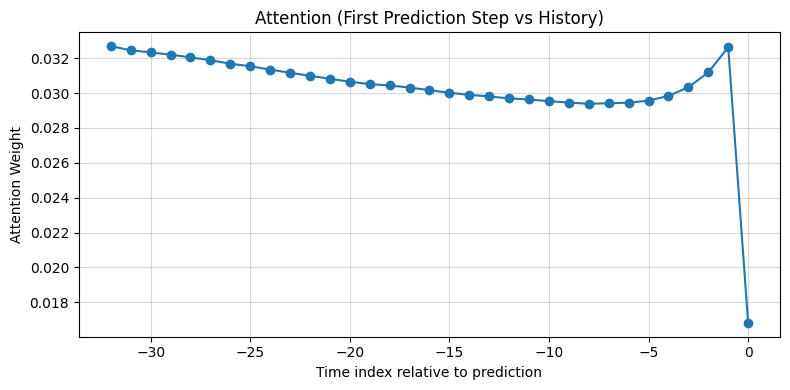

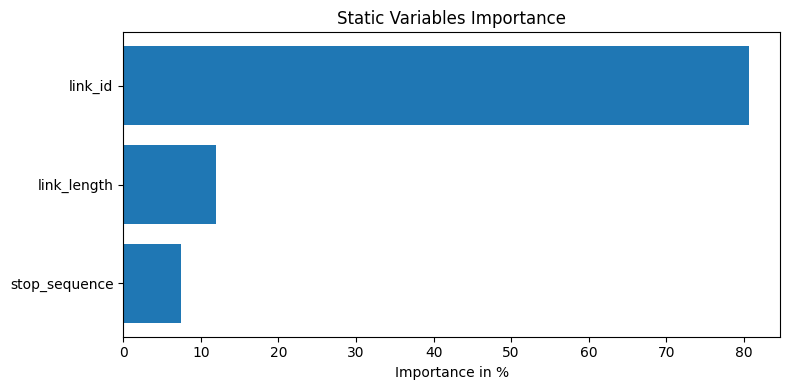

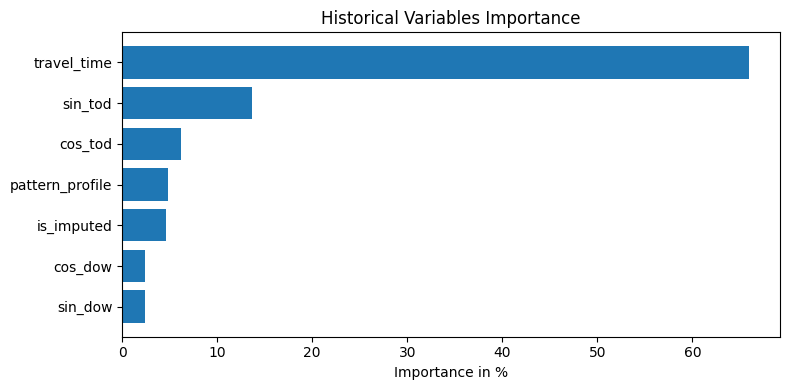

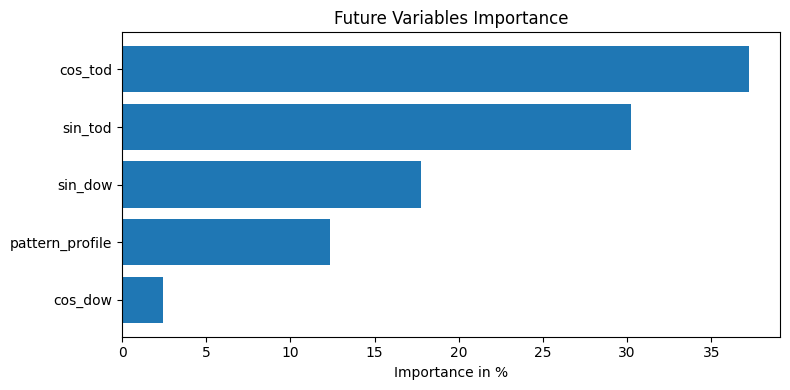

In [27]:
fixed_interval_model_trainer.plot_interpretation()

## Visualize kết quả không có calibration

In [28]:
NUM_DAYS_TO_PLOT = 3
NUM_SAMPLES_TO_PLOT = 96*NUM_DAYS_TO_PLOT # Muốn vẽ toàn bộ thì để num_samples=None

In [29]:
from bus_benchmark.experiments.utils import plot_test_predictions_quantiles_all_links

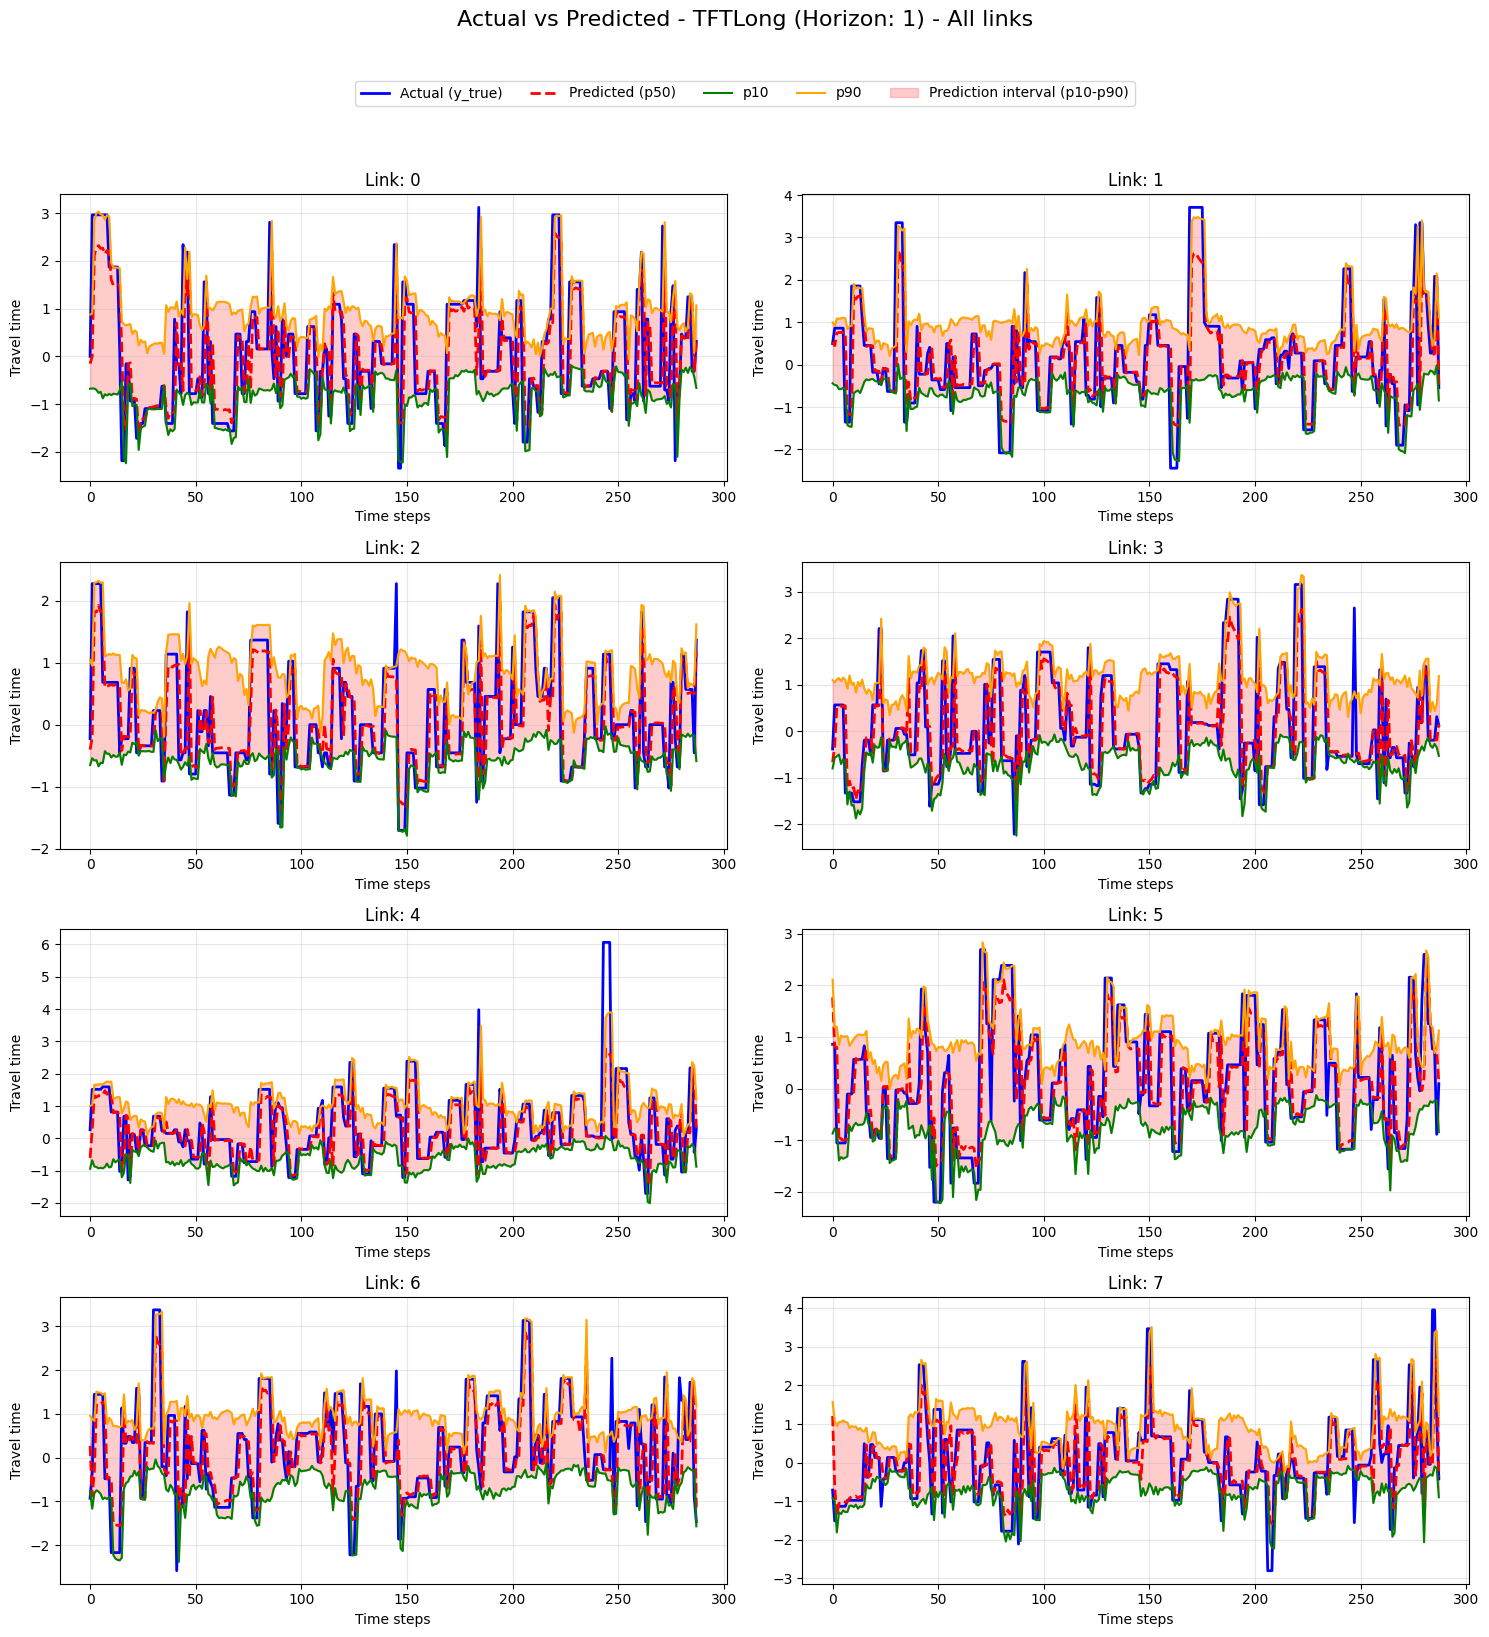

In [30]:
plot_test_predictions_quantiles_all_links(fixed_interval_model_trainer, horizon_idx=0, num_samples=NUM_SAMPLES_TO_PLOT)

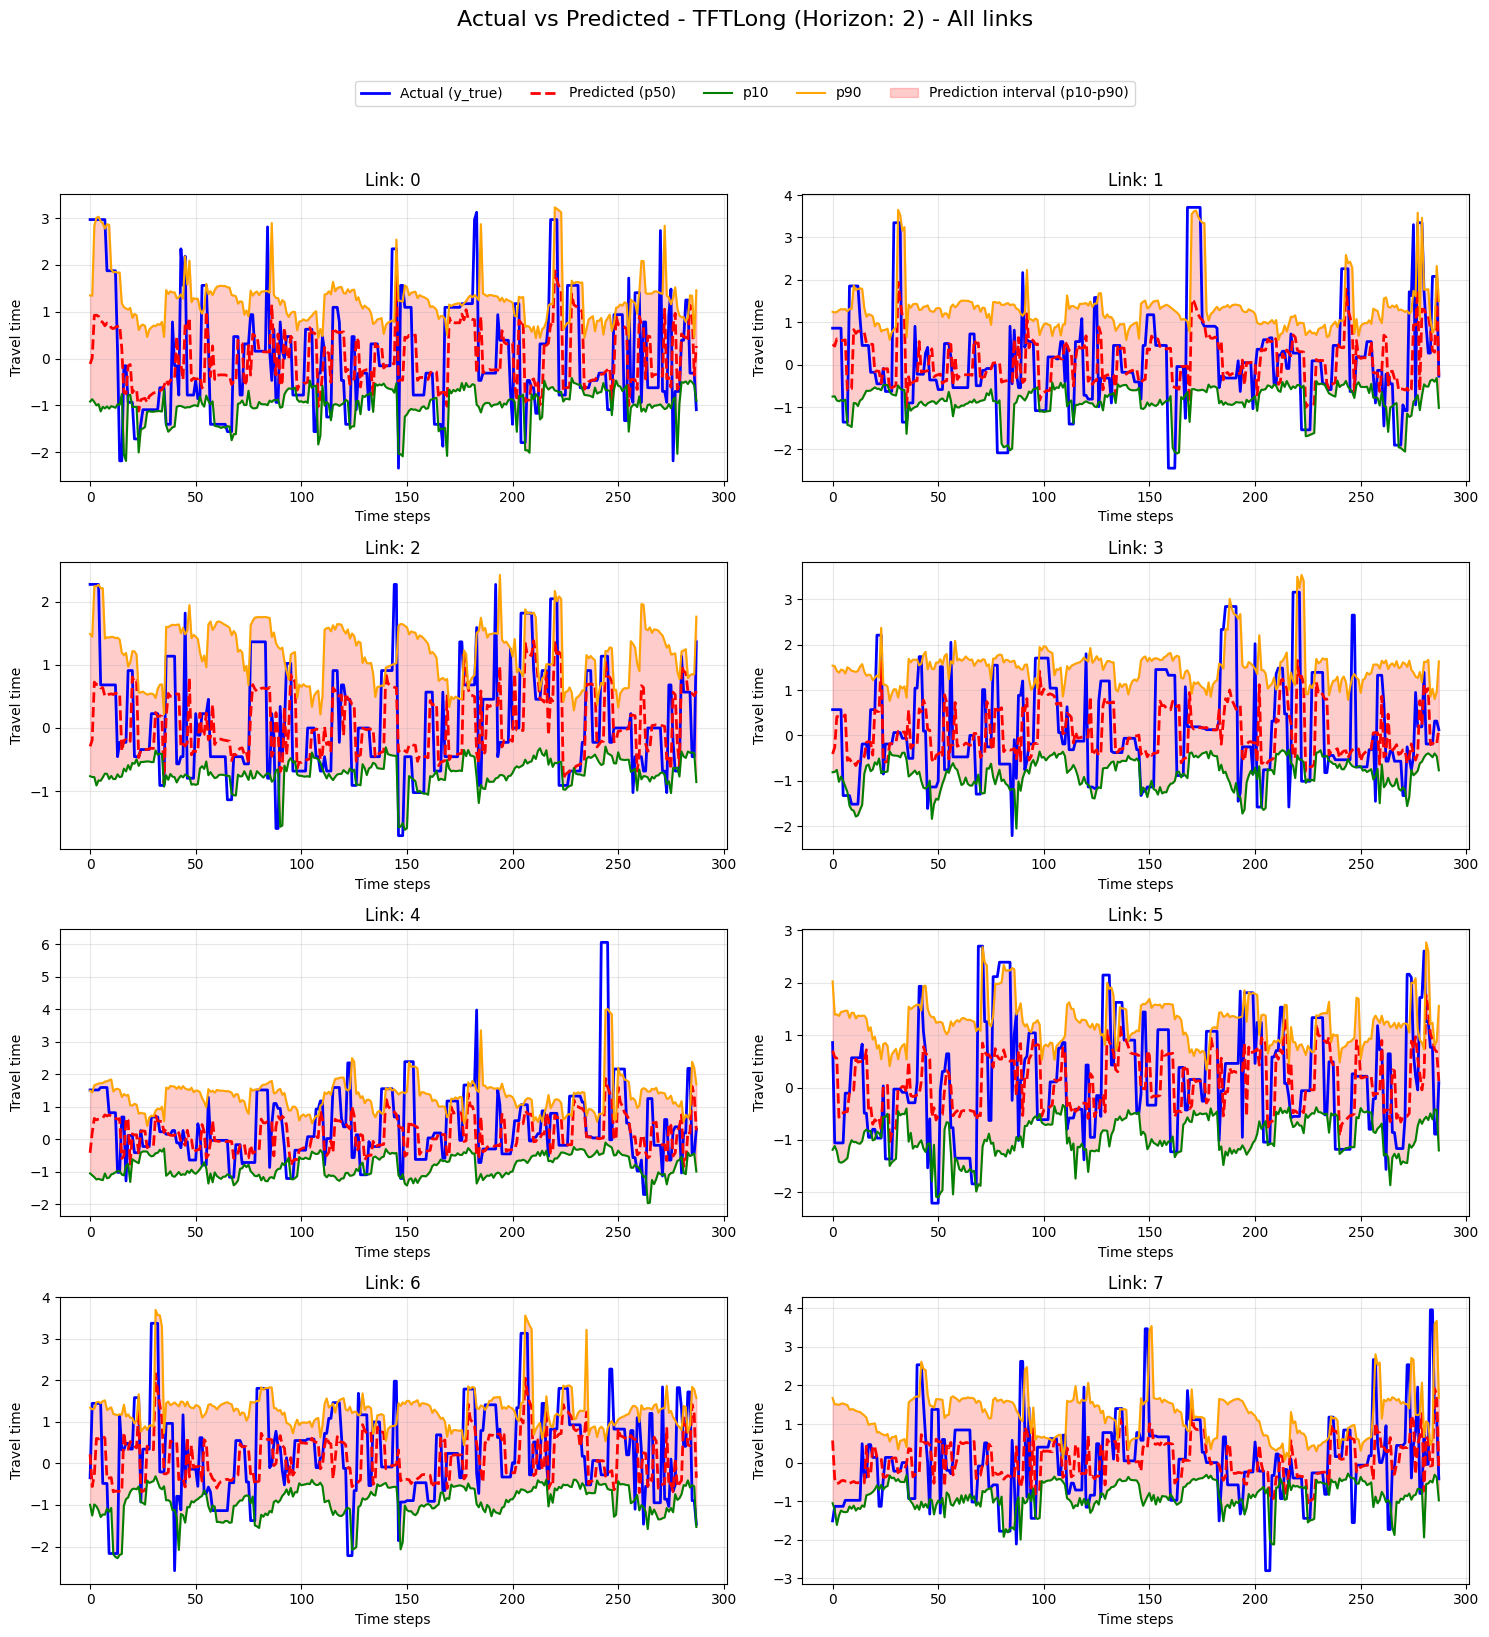

In [31]:
plot_test_predictions_quantiles_all_links(fixed_interval_model_trainer, horizon_idx=1, num_samples=NUM_SAMPLES_TO_PLOT)

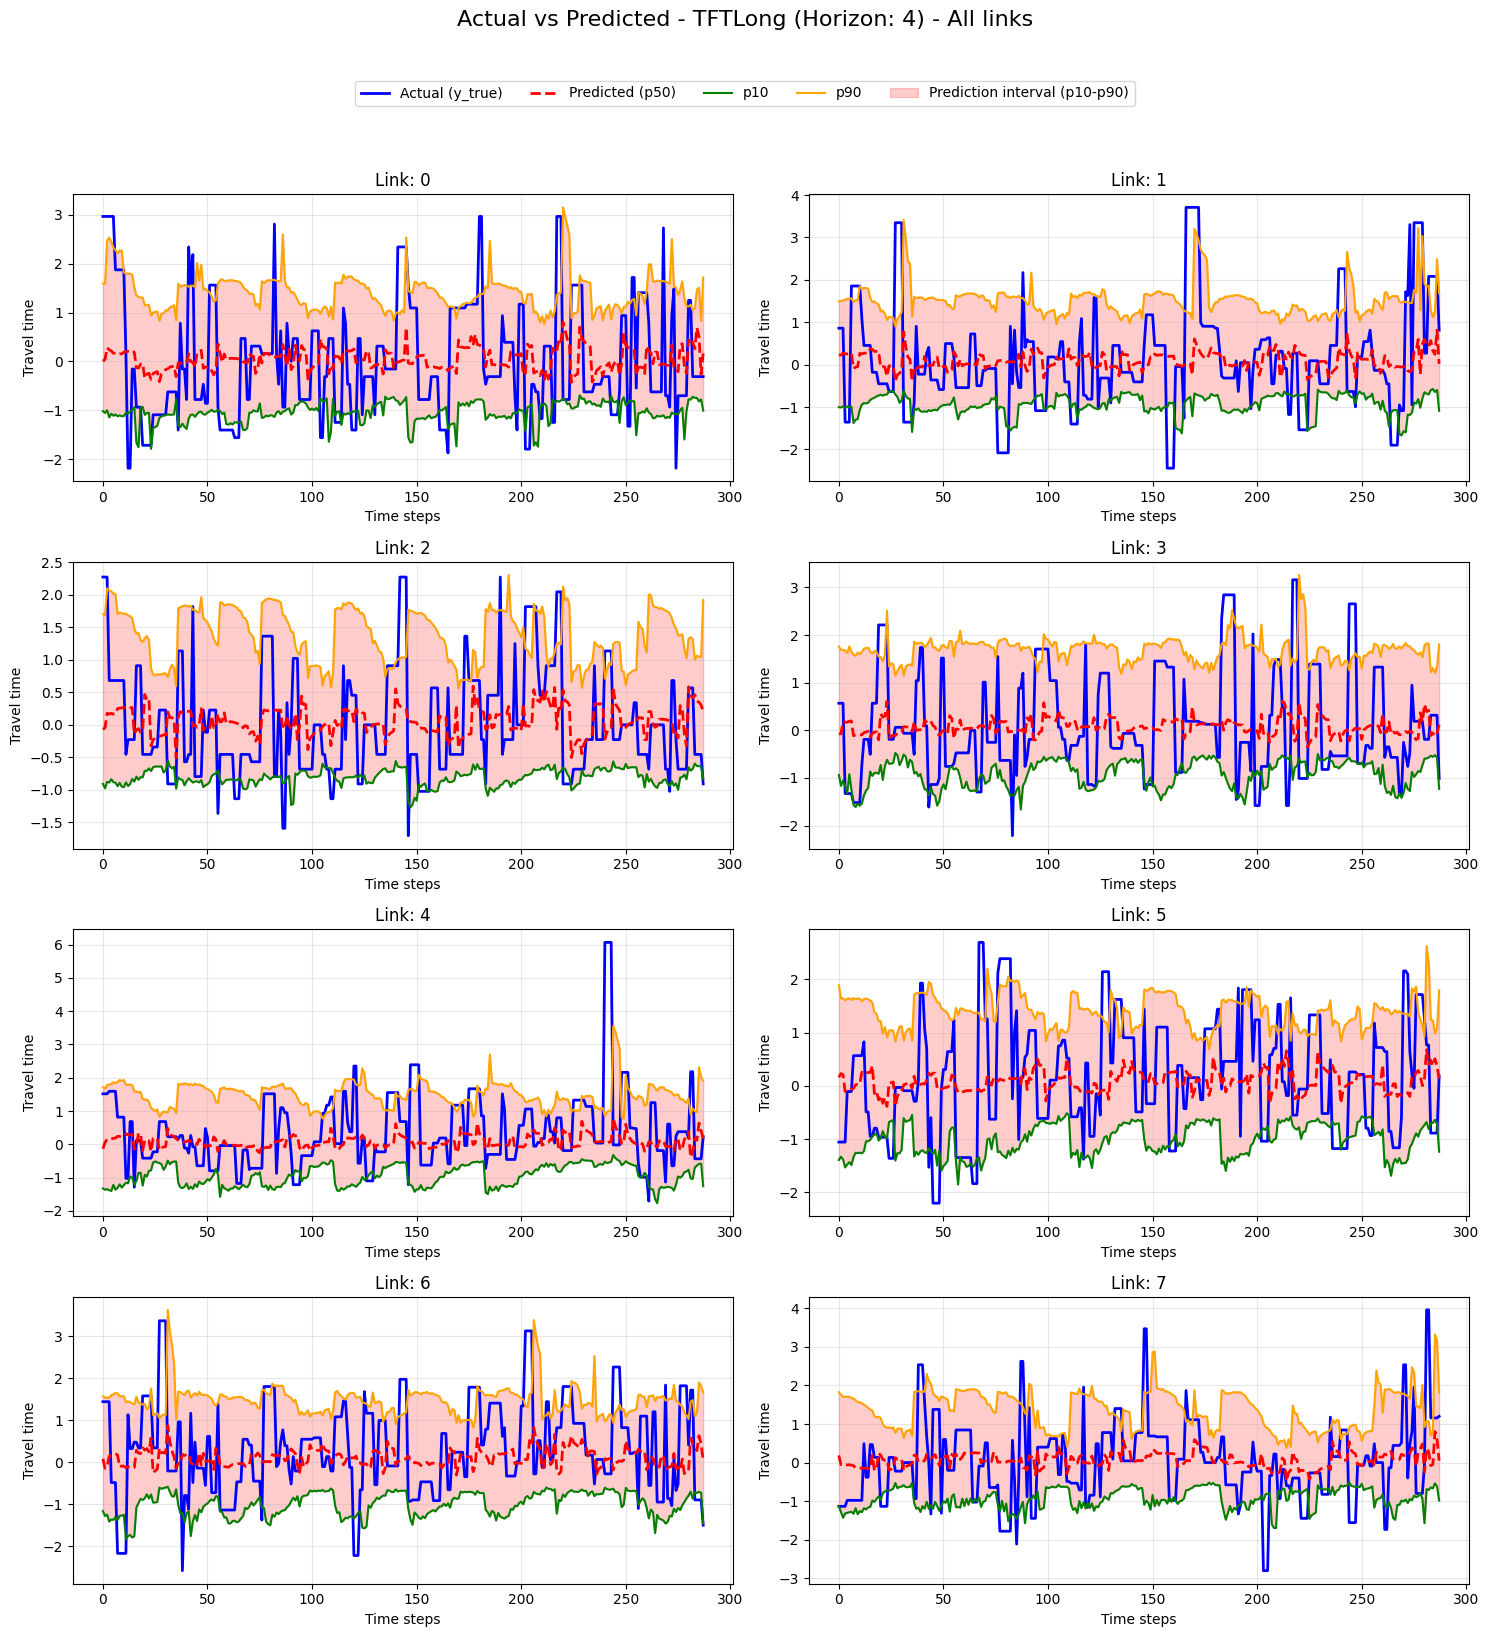

In [32]:
plot_test_predictions_quantiles_all_links(fixed_interval_model_trainer, horizon_idx=2, num_samples=NUM_SAMPLES_TO_PLOT)

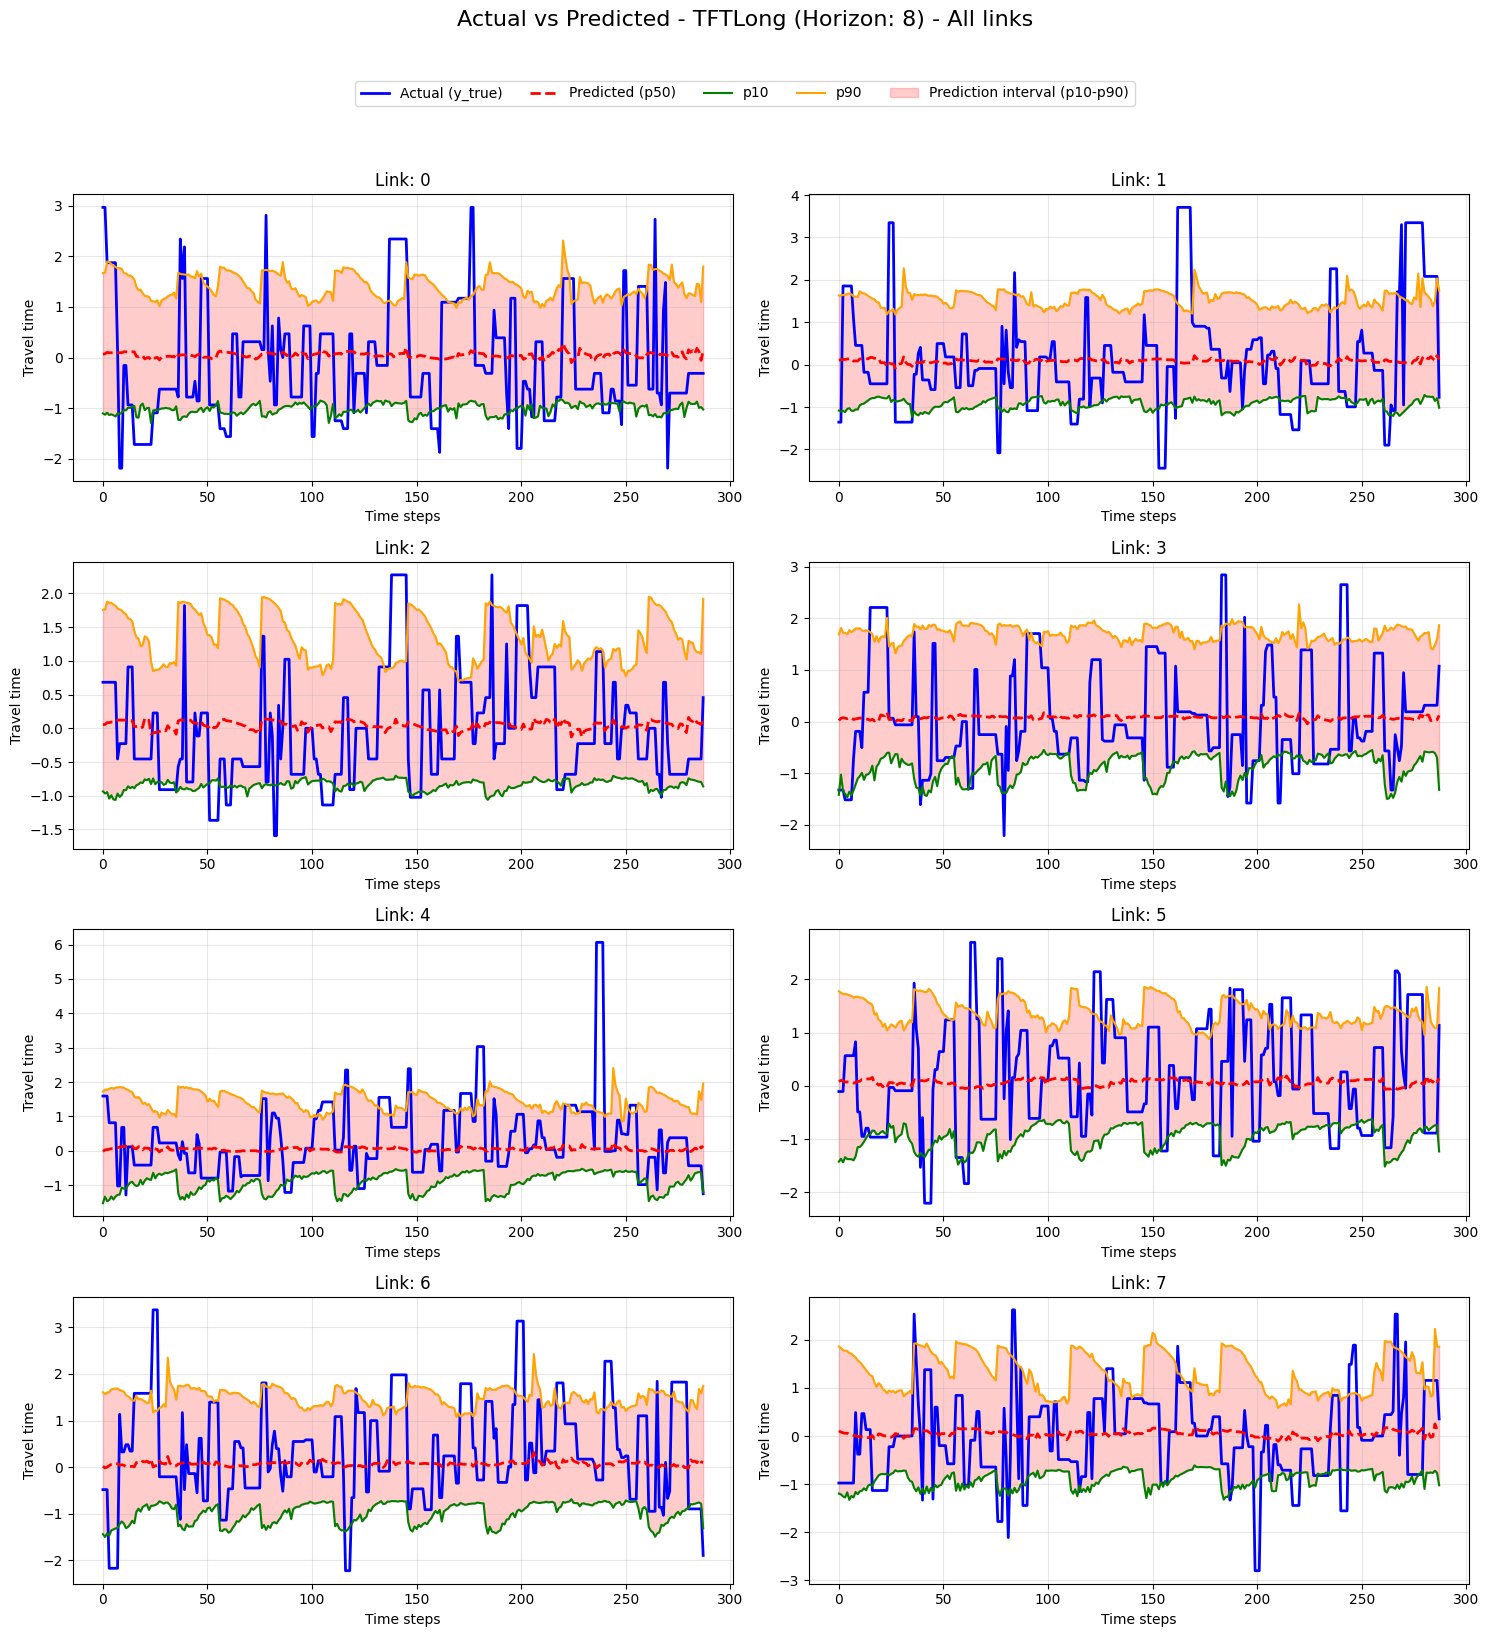

In [33]:
plot_test_predictions_quantiles_all_links(fixed_interval_model_trainer, horizon_idx=3, num_samples=NUM_SAMPLES_TO_PLOT)

## Calibration và evaluate

In [34]:
fixed_interval_model_trainer.use_conformal(
    nominal_coverage=0.80,
    conformal_per_horizon=True
)

INFO:bus_benchmark.experiments.model.tft_long_model_trainer:Conformal calibration enabled: nominal_coverage=80.0%, conformal_per_horizon=True


In [35]:
import time

start_test_time = time.time()
fixed_interval_model_trainer.evaluate_only()
end_test_time = time.time()

INFO:bus_benchmark.experiments.model.tft_long_model_trainer:Evaluating split 0/5 from checkpoint
INFO:bus_benchmark.experiments.tft_long_dataset:Created 25768 entity-based samples from 15998 time windows across 8 links
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 1 | MAE 9.8537 | RMSE 19.4854 | ICP 0.7857 | MIL 30.8714
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 2 | MAE 13.6864 | RMSE 21.8258 | ICP 0.7631 | MIL 39.1964
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 4 | MAE 14.8580 | RMSE 22.3236 | ICP 0.7525 | MIL 42.9432
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:  Horizon 8 | MAE 14.6228 | RMSE 21.8949 | ICP 0.7528 | MIL 41.9922
INFO:bus_benchmark.experiments.tft_long_dataset:Created 4280 entity-based samples from 2587 time windows across 8 links
INFO:bus_benchmark.experiments.model.tft_long_model_trainer:[Conformal Calibration (Target 80.0%)] Calib ICP 0.8064 (raw 0.7635) | Calib MIL 42.6161 (

In [36]:
test_time_seconds = end_test_time - start_test_time
test_time_minutes = test_time_seconds / 60
test_time_hours = test_time_minutes / 60

print(f"\n=========================================")
print(f"Hoàn thành calibration và test!")
print(f"Tổng thời gian: {test_time_seconds:.2f} giây")
print(f"Tương đương : {test_time_minutes:.2f} phút")
if test_time_hours > 1:
    print(f"Tương đương : {test_time_hours:.2f} giờ")
print(f"=========================================")


Hoàn thành calibration và test!
Tổng thời gian: 9.26 giây
Tương đương : 0.15 phút


## Visualize kết quả có calibration

In [37]:
from bus_benchmark.experiments.utils import plot_test_predictions_calibrated_quantiles_all_links

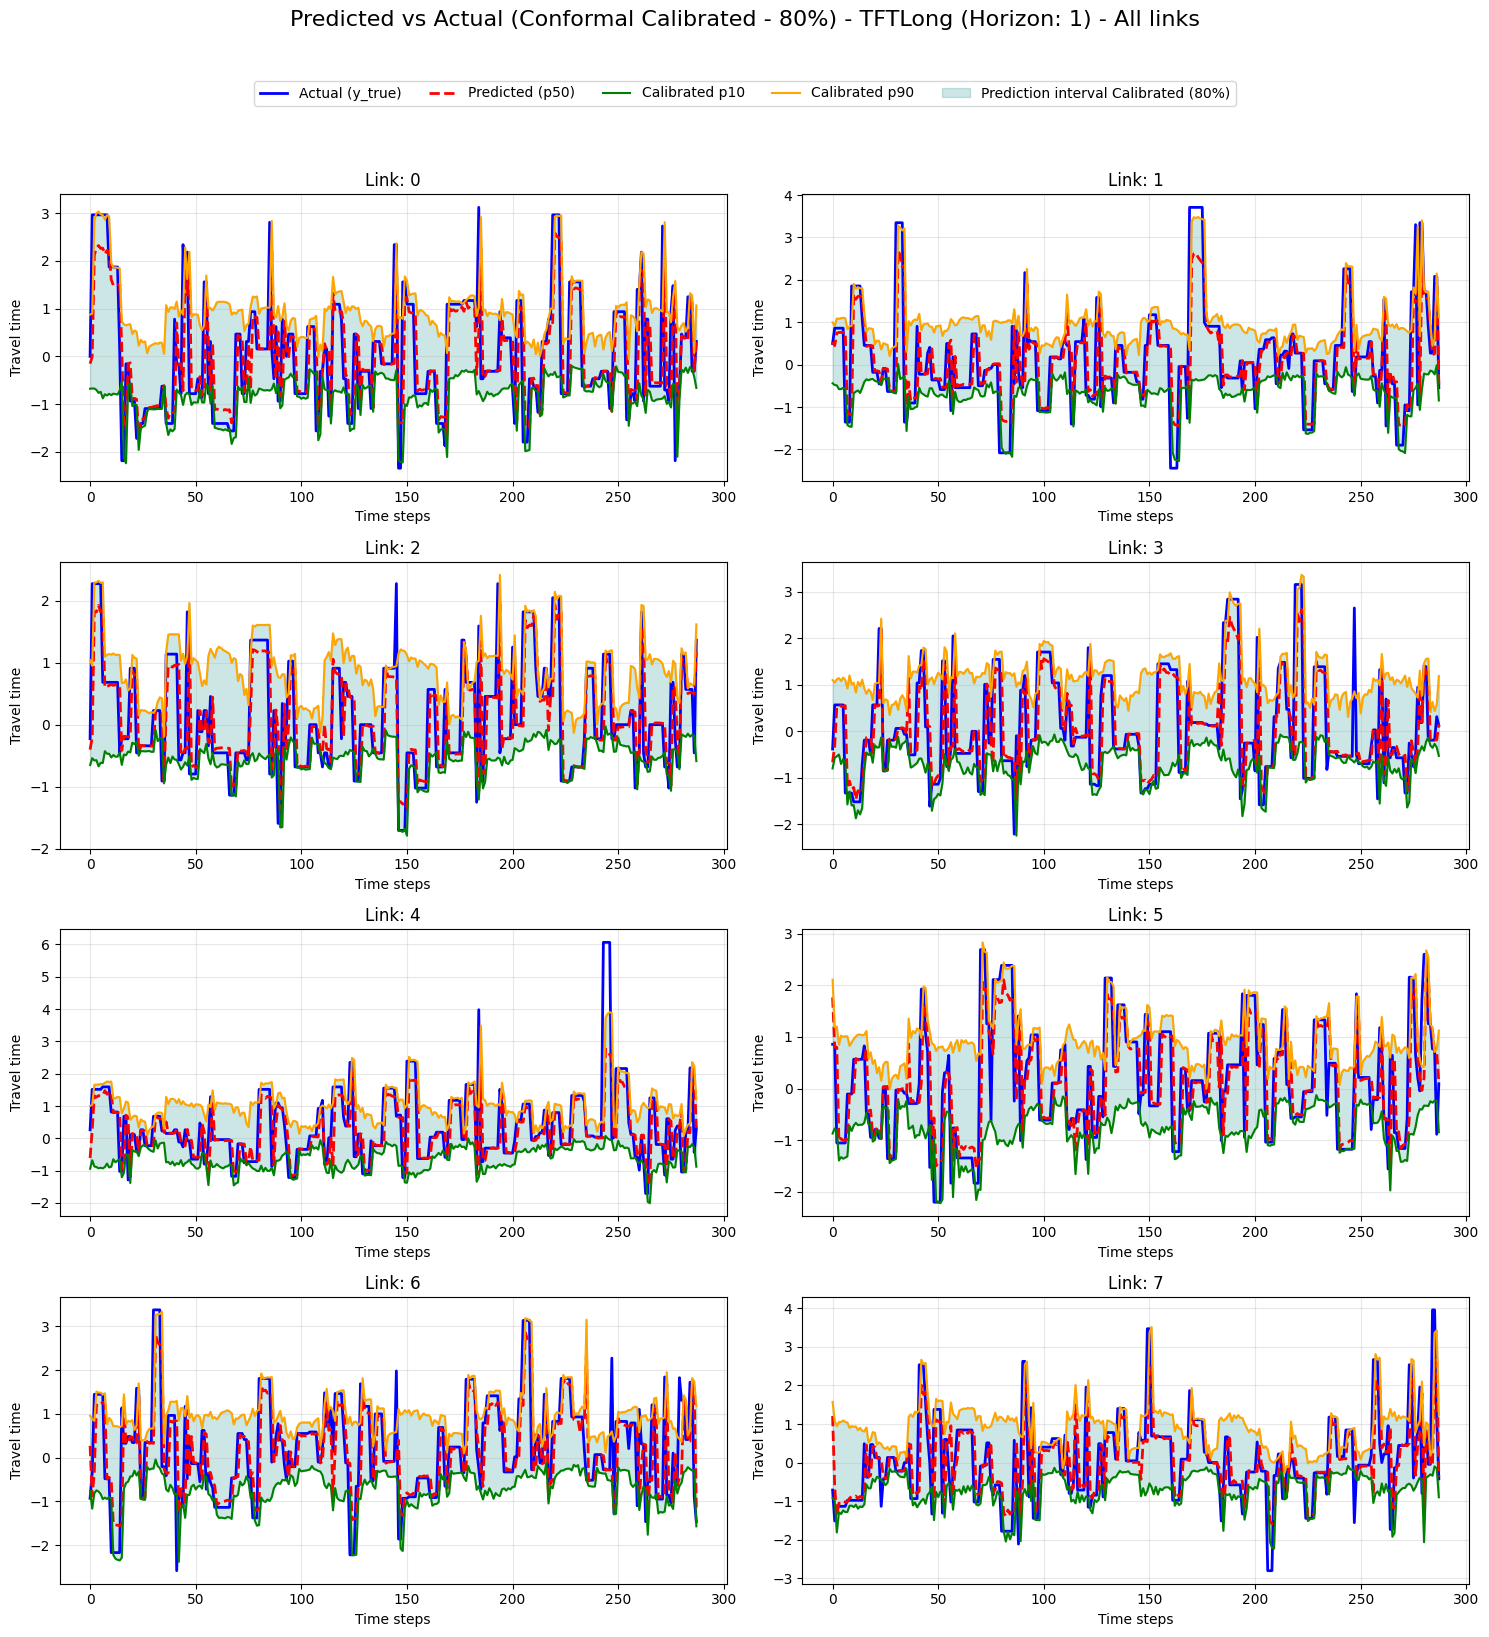

In [38]:
plot_test_predictions_calibrated_quantiles_all_links(fixed_interval_model_trainer, horizon_idx=0, num_samples=NUM_SAMPLES_TO_PLOT)